In [1]:
import os
for r, d, f in os.walk('/kaggle/input'):
    if 'part_A_final' in r and r.endswith('part_A_final'):
        print(r)

/kaggle/input/datasets/adii7860/shanghaitechparta/part_A_final


In [2]:
import os, glob, numpy as np, scipy.io as io, cv2
from PIL import Image
from scipy.ndimage import gaussian_filter
from scipy.spatial import KDTree

ROOT = '/kaggle/input/datasets/adii7860/shanghaitechparta/part_A_final'  # fix this
OUT = '/kaggle/working/density'
os.makedirs(OUT, exist_ok=True)

def density_map(shape, pts):
    d = np.zeros(shape, dtype=np.float32)
    n = len(pts)
    if n == 0: return d
    for p in pts:
        x, y = min(int(p[1]), shape[0]-1), min(int(p[0]), shape[1]-1)
        d[x, y] = 1
    if n == 1:
        return gaussian_filter(d, np.average(shape)/4)
    tree = KDTree(pts.copy(), leafsize=2048)
    dist, _ = tree.query(pts, k=4)
    out = np.zeros(shape, dtype=np.float32)
    for i, p in enumerate(pts):
        one = np.zeros(shape, dtype=np.float32)
        one[min(int(p[1]), shape[0]-1), min(int(p[0]), shape[1]-1)] = 1
        sigma = (dist[i][1] + dist[i][2] + dist[i][3]) * 0.1   # = mean of 3 NN * 0.3
        out += gaussian_filter(one, sigma, mode='constant')
    return out

for split in ['train_data', 'test_data']:
    for img_path in sorted(glob.glob(f'{ROOT}/{split}/images/*.jpg')):
        name = os.path.basename(img_path)[:-4]
        mat = io.loadmat(f'{ROOT}/{split}/ground_truth/GT_{name}.mat')
        pts = mat['image_info'][0, 0][0, 0][0]
        img = Image.open(img_path)
        dm = density_map((img.size[1], img.size[0]), pts)
        np.save(f'{OUT}/{split}_{name}_den.npy', dm)
        np.save(f'{OUT}/{split}_{name}_cnt.npy', np.array(len(pts)))

In [3]:
import glob, numpy as np
OUT = '/kaggle/working/density'
print('den files:', len(glob.glob(f'{OUT}/*_den.npy')), '| cnt files:', len(glob.glob(f'{OUT}/*_cnt.npy')))

for n in ['train_data_IMG_1', 'train_data_IMG_50', 'test_data_IMG_1']:
    d = np.load(f'{OUT}/{n}_den.npy'); c = np.load(f'{OUT}/{n}_cnt.npy')
    print(n, '-> density sum:', round(float(d.sum()), 2), '| true count:', int(c))

den files: 482 | cnt files: 482
train_data_IMG_1 -> density sum: 1544.83 | true count: 1546
train_data_IMG_50 -> density sum: 2332.02 | true count: 2348
test_data_IMG_1 -> density sum: 171.83 | true count: 172


In [4]:
import os, glob, random, csv, json, numpy as np, cv2, torch, torch.nn as nn
from PIL import Image
from torchvision import models, transforms
from torch.utils.data import Dataset, DataLoader

ROOT = '/kaggle/input/datasets/adii7860/shanghaitechparta/part_A_final'
OUT = '/kaggle/working/density'

norm = transforms.Compose([transforms.ToTensor(),
        transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])])

class Crowd(Dataset):
    def __init__(self, split, train):
        self.split, self.train = split, train
        self.names = sorted(os.path.basename(p)[:-4] for p in glob.glob(f'{ROOT}/{split}/images/*.jpg'))
    def __len__(self): return len(self.names)
    def __getitem__(self, i):
        n = self.names[i]
        img = Image.open(f'{ROOT}/{self.split}/images/{n}.jpg').convert('RGB')
        den = np.load(f'{OUT}/{self.split}_{n}_den.npy')
        cnt = float(np.load(f'{OUT}/{self.split}_{n}_cnt.npy'))
        if self.train:
            w, h = img.size
            cw, ch = w//2, h//2
            x, y = random.randint(0, w-cw), random.randint(0, h-ch)
            img = img.crop((x, y, x+cw, y+ch)); den = den[y:y+ch, x:x+cw]
            if random.random() < 0.5:
                img = img.transpose(Image.FLIP_LEFT_RIGHT); den = den[:, ::-1].copy()
        h8, w8 = den.shape[0]//8, den.shape[1]//8
        den = cv2.resize(den, (w8, h8), interpolation=cv2.INTER_CUBIC) * 64
        return norm(img), torch.from_numpy(den).unsqueeze(0).float(), cnt

class CSRNet(nn.Module):
    def __init__(self):
        super().__init__()
        vgg = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1)
        self.frontend = nn.Sequential(*list(vgg.features.children())[:23])
        cfg, layers, in_c = [512,512,512,256,128,64], [], 512
        for c in cfg:
            layers += [nn.Conv2d(in_c, c, 3, padding=2, dilation=2), nn.ReLU(inplace=True)]
            in_c = c
        self.backend = nn.Sequential(*layers)
        self.out = nn.Conv2d(64, 1, 1)
        for m in list(self.backend.modules()) + [self.out]:
            if isinstance(m, nn.Conv2d):
                nn.init.normal_(m.weight, std=0.01); nn.init.constant_(m.bias, 0)
    def forward(self, x): return self.out(self.backend(self.frontend(x)))

# quick check
ds = Crowd('train_data', True)
img, den, cnt = ds[0]
print(img.shape, den.shape, 'den sum:', den.sum().item(), '| true count of full image:', cnt)
print('GPU:', torch.cuda.is_available())

torch.Size([3, 384, 512]) torch.Size([1, 48, 64]) den sum: 761.1994018554688 | true count of full image: 1546.0
GPU: True


In [6]:
dev = 'cuda'
model = CSRNet().to(dev)
crit = nn.MSELoss(reduction='sum')
opt = torch.optim.SGD(model.parameters(), lr=1e-6, momentum=0.95, weight_decay=5e-4)

tr = DataLoader(Crowd('train_data', True), batch_size=1, shuffle=True, num_workers=2)
te = DataLoader(Crowd('test_data', False), batch_size=1, num_workers=2)

def evaluate():
    model.eval(); ae = se = 0
    with torch.no_grad():
        for img, _, cnt in te:
            pred = model(img.to(dev)).sum().item()
            ae += abs(pred - cnt.item()); se += (pred - cnt.item())**2
    return ae/len(te), (se/len(te))**0.5

EPOCHS = 300        # test ke baad 300 kar dena
best = 1e9
log = open('/kaggle/working/train_log.csv', 'w', newline=''); w = csv.writer(log)
w.writerow(['epoch','train_loss','test_mae','test_rmse'])
for ep in range(EPOCHS):
    model.train(); tot = 0
    for img, den, _ in tr:
        img, den = img.to(dev), den.to(dev)
        loss = crit(model(img), den)
        opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item()
    mae, rmse = evaluate()
    w.writerow([ep, tot/len(tr), mae, rmse]); log.flush()
    print(f'ep {ep} loss {tot/len(tr):.1f} MAE {mae:.2f} RMSE {rmse:.2f}')
    if mae < best:
        best = mae; torch.save(model.state_dict(), '/kaggle/working/csrnet_partA_best.pth')
    torch.save({'ep':ep,'m':model.state_dict(),'o':opt.state_dict(),'best':best}, '/kaggle/working/last.pth')
json.dump({'best_mae': best}, open('/kaggle/working/results.json','w'))

ep 0 loss 143.1 MAE 312.73 RMSE 407.39
ep 1 loss 138.3 MAE 473.11 RMSE 582.42
ep 2 loss 134.7 MAE 293.24 RMSE 384.91
ep 3 loss 128.6 MAE 218.77 RMSE 318.37
ep 4 loss 121.4 MAE 196.88 RMSE 251.39
ep 5 loss 120.6 MAE 276.23 RMSE 373.29
ep 6 loss 127.6 MAE 216.66 RMSE 328.41
ep 7 loss 114.9 MAE 216.63 RMSE 310.23
ep 8 loss 114.1 MAE 128.29 RMSE 201.86
ep 9 loss 96.4 MAE 227.11 RMSE 329.33
ep 10 loss 159.9 MAE 304.70 RMSE 392.34
ep 11 loss 100.6 MAE 204.87 RMSE 299.27
ep 12 loss 121.1 MAE 190.56 RMSE 282.38
ep 13 loss 118.7 MAE 376.77 RMSE 458.31
ep 14 loss 114.9 MAE 163.21 RMSE 241.40
ep 15 loss 114.3 MAE 242.23 RMSE 322.07
ep 16 loss 113.5 MAE 172.38 RMSE 261.05
ep 17 loss 103.7 MAE 178.77 RMSE 243.62
ep 18 loss 108.2 MAE 191.84 RMSE 263.20
ep 19 loss 120.6 MAE 168.94 RMSE 246.99
ep 20 loss 119.7 MAE 236.71 RMSE 329.22
ep 21 loss 94.5 MAE 265.30 RMSE 318.31
ep 22 loss 77.0 MAE 114.17 RMSE 166.15
ep 23 loss 106.3 MAE 132.02 RMSE 186.31
ep 24 loss 82.1 MAE 113.88 RMSE 163.85
ep 25 loss 90.

In [7]:
 model = CSRNet().to(dev)
model.load_state_dict(torch.load('/kaggle/working/csrnet_partA_best.pth'))
opt = torch.optim.SGD(model.parameters(), lr=1e-7, momentum=0.95, weight_decay=5e-4)

print('start MAE:', evaluate())   # ~78.92 aana chahiye

EPOCHS_FT, best_ft = 60, 1e9
log = open('/kaggle/working/train_log_finetune.csv', 'w', newline=''); w = csv.writer(log)
w.writerow(['epoch','train_loss','test_mae','test_rmse'])
for ep in range(EPOCHS_FT):
    model.train(); tot = 0
    for img, den, _ in tr:
        img, den = img.to(dev), den.to(dev)
        loss = crit(model(img), den)
        opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item()
    mae, rmse = evaluate()
    w.writerow([ep, tot/len(tr), mae, rmse]); log.flush()
    print(f'ft ep {ep} loss {tot/len(tr):.1f} MAE {mae:.2f} RMSE {rmse:.2f}')
    if mae < best_ft:
        best_ft = mae
        torch.save(model.state_dict(), '/kaggle/working/csrnet_partA_best_ft.pth')
json.dump({'best_mae_stage1': best, 'best_mae_finetune': best_ft}, open('/kaggle/working/results_ft.json','w'))

start MAE: (78.91802771012861, 123.65363465304607)
ft ep 0 loss 60.2 MAE 82.07 RMSE 125.33
ft ep 1 loss 62.4 MAE 80.21 RMSE 123.85
ft ep 2 loss 54.8 MAE 79.92 RMSE 124.48
ft ep 3 loss 55.2 MAE 79.53 RMSE 124.81
ft ep 4 loss 61.5 MAE 80.10 RMSE 124.74
ft ep 5 loss 82.3 MAE 79.80 RMSE 125.17
ft ep 6 loss 60.7 MAE 83.39 RMSE 125.53
ft ep 7 loss 74.1 MAE 79.57 RMSE 124.06
ft ep 8 loss 55.6 MAE 81.80 RMSE 124.94
ft ep 9 loss 61.7 MAE 81.52 RMSE 126.10
ft ep 10 loss 58.2 MAE 81.97 RMSE 125.97
ft ep 11 loss 52.4 MAE 81.07 RMSE 124.90
ft ep 12 loss 51.4 MAE 80.63 RMSE 125.43
ft ep 13 loss 49.4 MAE 83.34 RMSE 126.41
ft ep 14 loss 48.3 MAE 79.66 RMSE 124.67
ft ep 15 loss 52.5 MAE 82.20 RMSE 125.50
ft ep 16 loss 62.3 MAE 81.19 RMSE 124.43
ft ep 17 loss 58.8 MAE 83.49 RMSE 125.60
ft ep 18 loss 53.0 MAE 81.35 RMSE 124.95
ft ep 19 loss 59.8 MAE 82.62 RMSE 124.84
ft ep 20 loss 61.0 MAE 81.34 RMSE 124.59
ft ep 21 loss 54.9 MAE 80.40 RMSE 124.61
ft ep 22 loss 56.6 MAE 81.55 RMSE 125.58
ft ep 23 loss 50

In [9]:
import pandas as pd
model = CSRNet().to(dev)
model.load_state_dict(torch.load('/kaggle/working/csrnet_partA_best.pth'))
model.eval()

names = te.dataset.names
rows = []
with torch.no_grad():
    for i, (img, _, cnt) in enumerate(te):
        pred = model(img.to(dev)).sum().item()
        rows.append([names[i], cnt.item(), round(pred, 2), round(abs(pred - cnt.item()), 2)])

df = pd.DataFrame(rows, columns=['image', 'gt_count', 'pred_count', 'abs_error'])
df.to_csv('/kaggle/working/test_predictions.csv', index=False)

mae = df.abs_error.mean()
rmse = (df.abs_error**2).mean()**0.5
print(f'FINAL  MAE {mae:.2f}  RMSE {rmse:.2f}')
print(df.sort_values('abs_error', ascending=False).head(5))   # sabse bure 5 images

FINAL  MAE 78.92  RMSE 123.65
       image  gt_count  pred_count  abs_error
160    IMG_8    1326.0      677.62     648.38
172   IMG_90    2256.0     1758.07     497.93
128   IMG_50    1006.0      584.88     421.12
73   IMG_165    1581.0     1215.16     365.84
174   IMG_92    1366.0     1043.66     322.34


In [13]:
import json
mse_nae = (df.abs_error / df.gt_count.clip(lower=1)).mean()   # normalized error
json.dump({
    'model': 'CSRNet', 'dataset': 'ShanghaiTech Part A',
    'best_epoch': 233, 'test_mae': round(mae, 2), 'test_rmse': round(rmse, 2),
    'mean_relative_error': round(float(mse_nae), 3),
    'train_images': 300, 'test_images': 182,
    'stage1': 'SGD lr1e-6 mom0.95 wd5e-4, 300 epochs, crop+flip, batch 1',
    'stage2_finetune': 'lr1e-7, 60 epochs, no improvement (best 78.93)'
}, open('/kaggle/working/results_final.json', 'w'), indent=2)

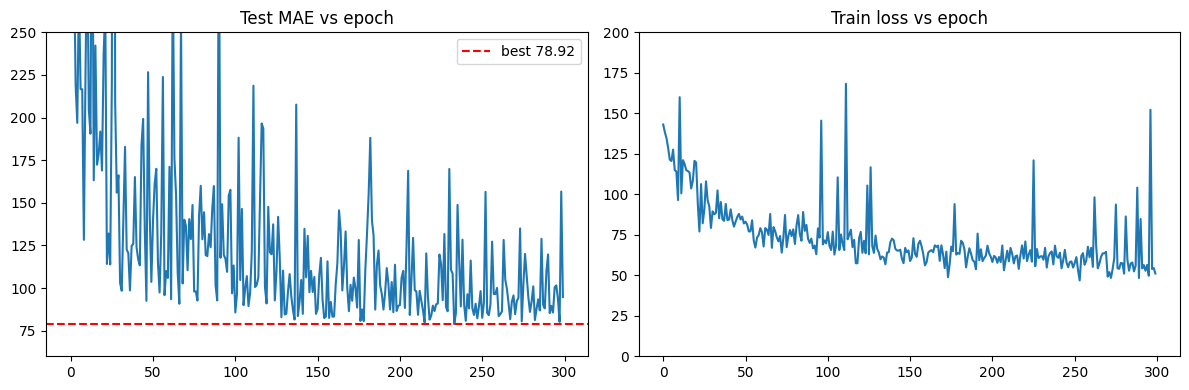

In [14]:
import matplotlib.pyplot as plt
log = pd.read_csv('/kaggle/working/train_log.csv')
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(log.epoch, log.test_mae); ax[0].axhline(78.92, ls='--', c='r', label='best 78.92')
ax[0].set_ylim(60, 250); ax[0].set_title('Test MAE vs epoch'); ax[0].legend()
ax[1].plot(log.epoch, log.train_loss); ax[1].set_title('Train loss vs epoch'); ax[1].set_ylim(0, 200)
plt.tight_layout(); plt.savefig('/kaggle/working/mae_curve.png', dpi=150)

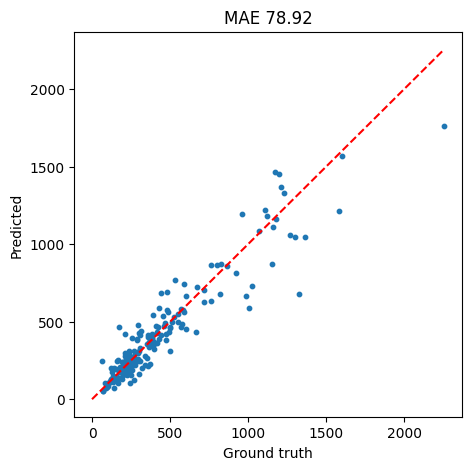

In [15]:
plt.figure(figsize=(5, 5))
plt.scatter(df.gt_count, df.pred_count, s=10)
m = max(df.gt_count.max(), df.pred_count.max())
plt.plot([0, m], [0, m], 'r--'); plt.xlabel('Ground truth'); plt.ylabel('Predicted')
plt.title(f'MAE {mae:.2f}'); plt.savefig('/kaggle/working/pred_vs_gt.png', dpi=150)

In [17]:
os.makedirs('/kaggle/working/samples', exist_ok=True)
for n in ['IMG_1', 'IMG_50', 'IMG_100']:
    img = Image.open(f'{ROOT}/test_data/images/{n}.jpg').convert('RGB')
    with torch.no_grad():
        d = model(norm(img).unsqueeze(0).to(dev))[0, 0].cpu().numpy()
    gt = np.load(f'{OUT}/test_data_{n}_cnt.npy')
    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    ax[0].imshow(img); ax[0].set_title(f'GT {int(gt)}'); ax[0].axis('off')
    ax[1].imshow(d, cmap='jet'); ax[1].set_title(f'Pred {d.sum():.0f}'); ax[1].axis('off')
    plt.savefig(f'/kaggle/working/samples/{n}.png', dpi=120); plt.close()

In [18]:
import shutil, os, glob

EXP = '/kaggle/working/export/csrnet_partA_v1'
os.makedirs(f'{EXP}/results', exist_ok=True)
os.makedirs(f'{EXP}/weights', exist_ok=True)

shutil.copy('/kaggle/working/csrnet_partA_best.pth', f'{EXP}/weights/')
for f in ['train_log.csv', 'train_log_finetune.csv', 'results.json', 'results_ft.json',
          'results_final.json', 'test_predictions.csv', 'mae_curve.png', 'pred_vs_gt.png']:
    p = f'/kaggle/working/{f}'
    if os.path.exists(p): shutil.copy(p, f'{EXP}/results/')
    else: print('missing:', f)
shutil.copytree('/kaggle/working/samples', f'{EXP}/results/samples', dirs_exist_ok=True)

shutil.make_archive('/kaggle/working/csrnet_partA_v1', 'zip', '/kaggle/working/export')
print(os.path.getsize('/kaggle/working/csrnet_partA_v1.zip') / 1e6, 'MB')

61.400689 MB


In [19]:
from IPython.display import FileLink
FileLink('/kaggle/working/csrnet_partA_v1.zip')

/kaggle/working/csrnet_partA_v1.zip